# Week 4 — Time Series, Proportions & Hierarchies
**CDB601220 · Completed computational assignment (Parts A–E)**

All inputs are synthetic course data from Superior University Lahore. The original 17 attachments are preserved unchanged in `originals/`; runnable copies are in `data/` and the project root.

**Status:** All analysis and plots are provided. Part C's real-reader observations require a person: its timed collection and scoring cell is at the end, and the CSV explicitly marks both observations pending. Annual decomposition is attempted and its insufficient-history error explained. Optional Part F is not attempted because no external dataset was supplied or sourced. Add your name/roll number before submission and rename the ZIP `W4_<RollNo>.zip`.

## Run instructions
Extract the entire ZIP before opening this notebook. Install `requirements.txt`, select Python 3, and Run All. Figures are embedded below and exported at 300 dpi. Scripts reproduce the same results. Run Part D cleaning first because Part B depends on it. See `START_HERE.md` for the file map.

In [1]:
from pathlib import Path
import os, sys
assert Path('common.py').exists(), 'Open this notebook from its extracted W4_Assignment folder.'
sys.path.insert(0, str(Path.cwd()))
from IPython.display import display, Markdown

## Part D — Cleaning and dashboard

The seven-day window is chosen for the weekly cycle before inspecting alternative trends. Invalid sentinels are linearly interpolated only where bracketing observations exist; collector gaps are never filled in the dashboard. Interpolation is an assumption, not a recovered measurement.

In [2]:
from common import *
# Fix the seven-day window before examining alternative outcomes: it targets the weekly cycle.
WINDOW=7
d,h,daily,coverage,cleanlog=clean_sessions()
c,pos,neg,g,catlog=clean_catalogue()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12670 entries, 0 to 12669
Data columns (total 5 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   ts           12670 non-null  object
 1   sessions     12670 non-null  int64 
 2   orders       12670 non-null  int64 
 3   revenue_pkr  12670 non-null  int64 
 4   device       12670 non-null  object
dtypes: int64(3), object(2)
memory usage: 495.1+ KB
               count           mean  ...        75%        max
sessions     12670.0     947.951381  ...    1368.00     9811.0
orders       12670.0      30.016732  ...      42.00      304.0
revenue_pkr  12670.0  132564.968824  ...  182232.25  1652881.0

[3 rows x 8 columns]
device
Mobile     6994
Desktop    3452
mobile      883
Tablet      777
desktop     318
MOBILE      246
Name: count, dtype: int64
['2024-04-29 11:00:00', '2024-10-26 05:00:00', '2025-08-04 20:00:00', '2024-10-05 19:00:00', '2025-01-22 20:00:00', '05/10/2024 09:00', '2024-08-11 15

Strict complete-case seven-day estimates: 432 of 518


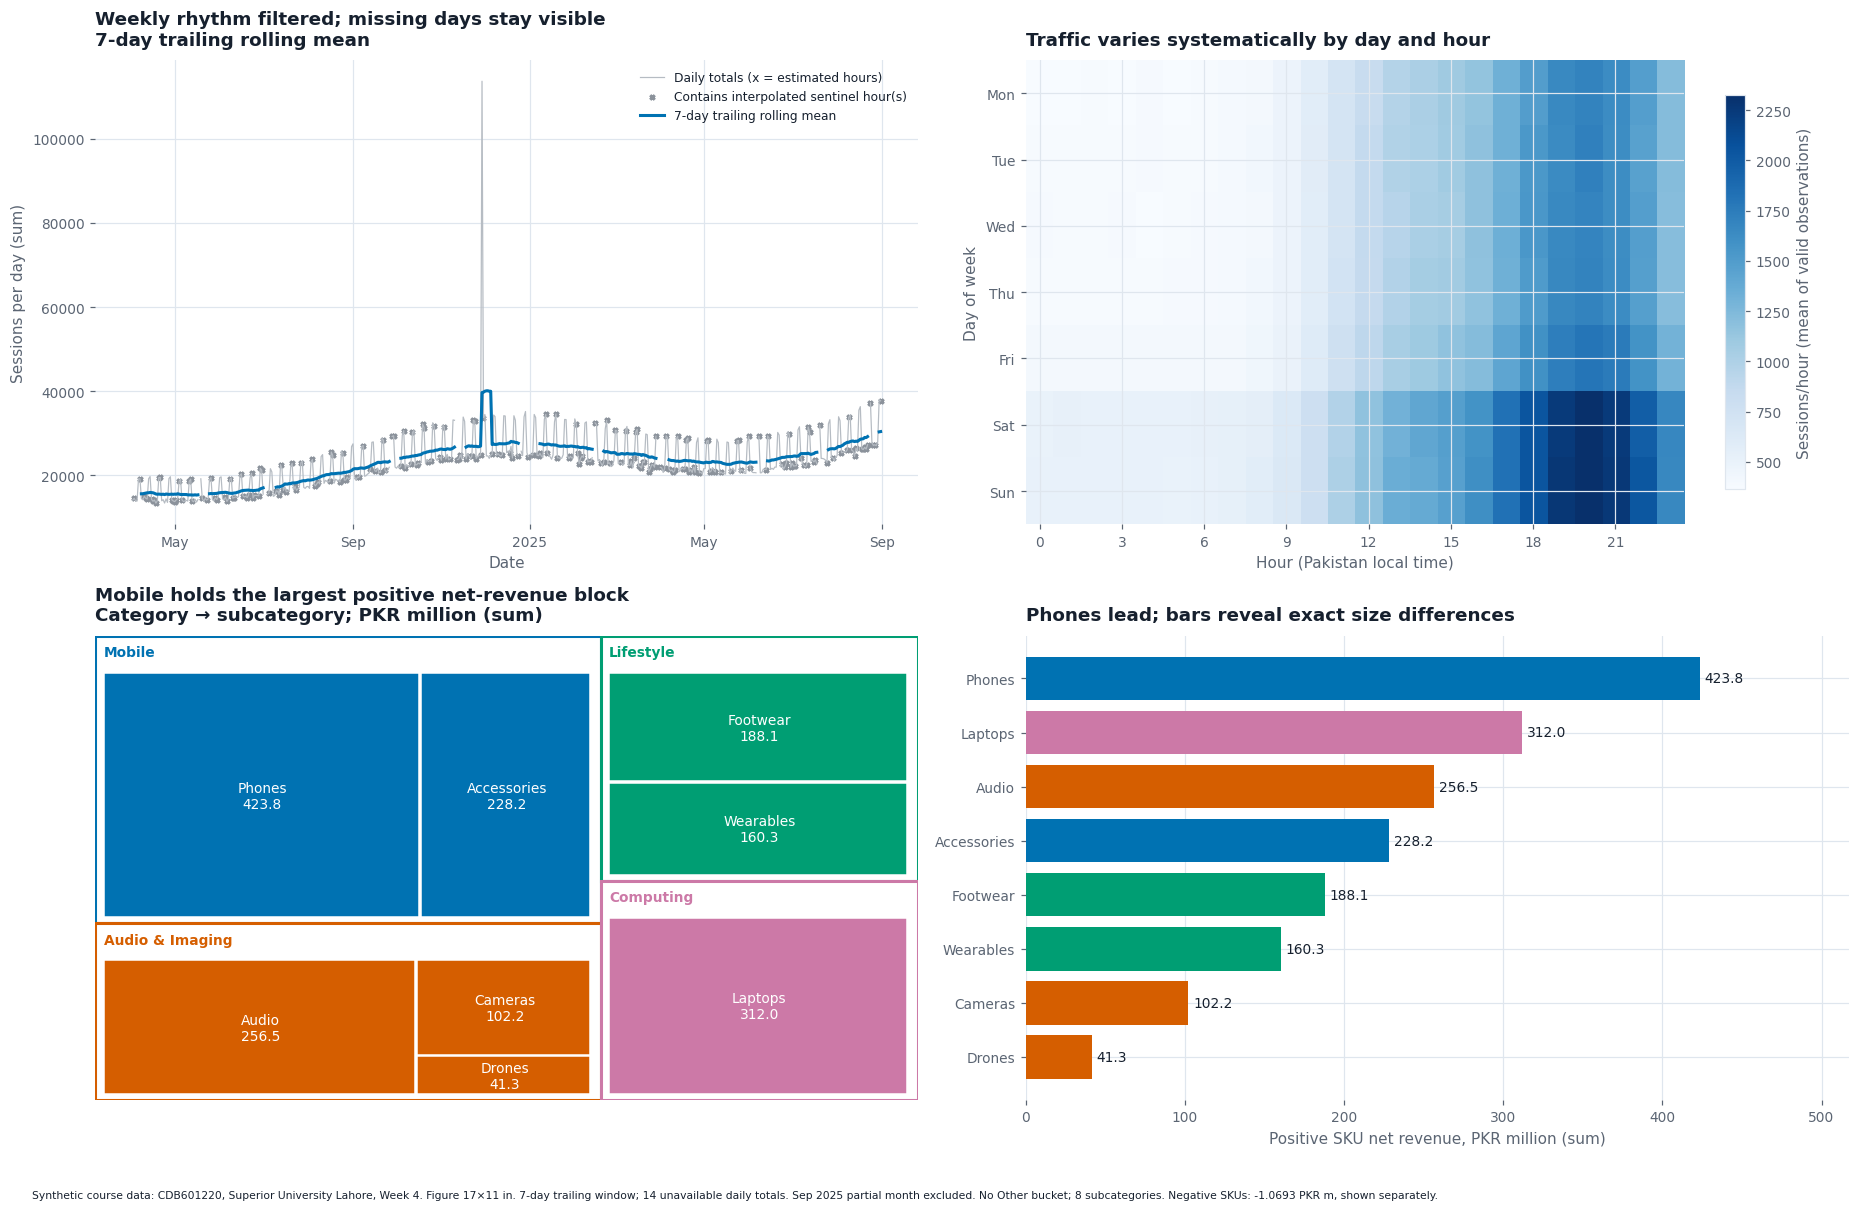

In [3]:
# Collector gaps remain missing; totals with sentinel interpolation are explicitly marked.
rolling=daily.rolling(WINDOW,min_periods=WINDOW).mean()
print('Strict complete-case seven-day estimates:',rolling.notna().sum(),'of',len(daily))
fig,axs=plt.subplots(2,2,figsize=(17,11))
a=axs[0,0];a.plot(daily.index,daily,color='#b6bcc3',lw=.8,label='Daily totals (x = estimated hours)')
estimated=h.estimated.resample('D').sum().reindex(daily.index).gt(0)
a.scatter(daily.index[estimated],daily[estimated],marker='x',s=9,color='#8b929b',label='Contains interpolated sentinel hour(s)')
a.plot(rolling.index,rolling,color=COL[0],label='7-day trailing rolling mean')
a.set(title='Weekly rhythm filtered; missing days stay visible\n7-day trailing rolling mean',ylabel='Sessions per day (sum)',xlabel='Date');a.legend(fontsize=8);dateaxis(a)
heat=d[d.index<daily.index.max()+pd.Timedelta(days=1)].copy();heat['weekday']=heat.index.dayofweek;heat['hour']=heat.index.hour
piv=heat.pivot_table(index='weekday',columns='hour',values='sessions',aggfunc='mean').reindex(index=range(7),columns=range(24))
a=axs[0,1];im=a.imshow(piv,cmap=vizlib.PALETTE['sequential'],aspect='auto');a.set(yticks=range(7),yticklabels=['Mon','Tue','Wed','Thu','Fri','Sat','Sun'],xticks=range(0,24,3),xlabel='Hour (Pakistan local time)',ylabel='Day of week',title='Traffic varies systematically by day and hour')
fig.colorbar(im,ax=a,label='Sessions/hour (mean of valid observations)',shrink=.85)
# Nested rectangles explicitly encode category -> subcategory containment.
import squarify
from matplotlib.patches import Rectangle
parents=g.groupby('category').value.sum().sort_values(ascending=False);colors=dict(zip(parents.index,COL))
a=axs[1,0];rects=squarify.squarify(squarify.normalize_sizes(parents.values,100,100),0,0,100,100)
for (parent,total),r in zip(parents.items(),rects):
    a.add_patch(Rectangle((r['x'],r['y']),r['dx'],r['dy'],facecolor='white',edgecolor=colors[parent],lw=2))
    a.text(r['x']+1,r['y']+2,parent,va='top',fontsize=9,fontweight='bold',color=colors[parent])
    sub=g[g.category==parent].sort_values('value',ascending=False)
    sr=squarify.squarify(squarify.normalize_sizes(sub.value,r['dx']-2,r['dy']-9),r['x']+1,r['y']+8,r['dx']-2,r['dy']-9)
    for row,q in zip(sub.itertuples(),sr):
        a.add_patch(Rectangle((q['x'],q['y']),q['dx']-.3,q['dy']-.3,facecolor=colors[parent],edgecolor='white'))
        a.text(q['x']+q['dx']/2,q['y']+q['dy']/2,f'{row.subcategory}\n{row.value:,.1f}',ha='center',va='center',fontsize=9,color='white')
a.set(xlim=(0,100),ylim=(100,0),title='Mobile holds the largest positive net-revenue block\nCategory → subcategory; PKR million (sum)');a.axis('off')
a=axs[1,1];s=g.sort_values('value');a.barh(s.subcategory,s.value,color=[colors[x] for x in s.category]);a.bar_label(a.containers[0],fmt='%.1f',padding=3,fontsize=9);a.set(xlim=(0,s.value.max()*1.22),xlabel='Positive SKU net revenue, PKR million (sum)',title='Phones lead; bars reveal exact size differences')
for ax in axs.flat:
    for spine in ax.spines.values():spine.set_visible(False)
finish(fig,'partD_figure.png',f'Figure 17×11 in. 7-day trailing window; {cleanlog["daily_gaps"]} unavailable daily totals. Sep 2025 partial month excluded. No Other bucket; 8 subcategories. Negative SKUs: {catlog["negative_net"]:.4f} PKR m, shown separately.')

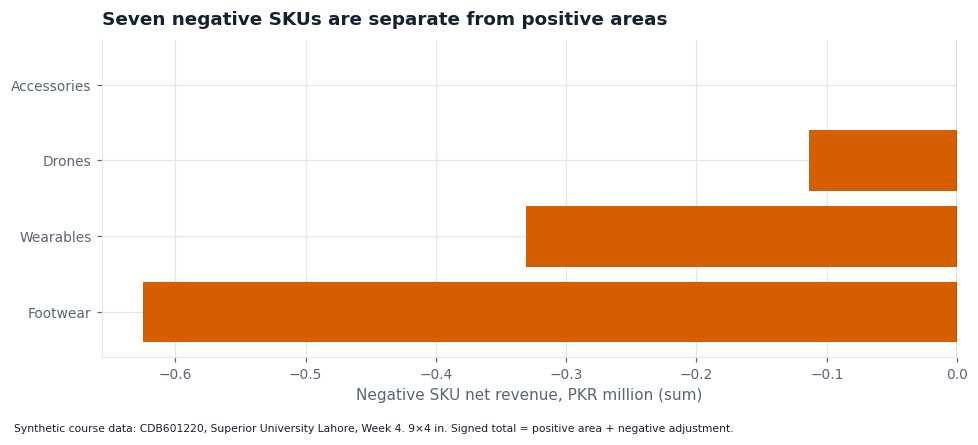

CVD function: (rgb, kind='deutan')


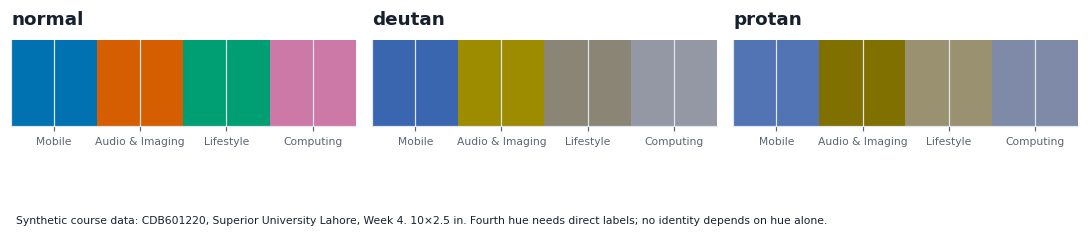

In [4]:
fig,ax=plt.subplots(figsize=(9,4));ns=neg.groupby('subcategory').net_revenue_pkr_m.sum().sort_values();ax.barh(ns.index,ns.values,color=COL[1]);ax.axvline(0,color='black',lw=.8);ax.set(title='Seven negative SKUs are separate from positive areas',xlabel='Negative SKU net revenue, PKR million (sum)');finish(fig,'negative_revenue.png','9×4 in. Signed total = positive area + negative adjustment.')
# CVD evidence uses the supplied toolkit, with direct labels supplementing the fourth hue.
print('CVD function:',__import__('inspect').signature(vizlib.simulate_cvd))
daily.to_csv(OUT/'clean_daily_sessions.csv',header=['sessions']);coverage.to_csv(OUT/'daily_valid_hour_counts.csv')
(OUT/'cleaning_audit.json').write_text(json.dumps({'sessions':cleanlog,'catalogue':catlog},indent=2,default=str))

from matplotlib.colors import to_rgb
fig,axs=plt.subplots(1,3,figsize=(10,2.5))
for ax,kind in zip(axs,['normal','deutan','protan']):
    rgb=np.array([to_rgb(x) for x in COL]);rgb=rgb if kind=='normal' else vizlib.simulate_cvd(rgb,kind=kind)
    ax.imshow(rgb[None,:,:]);ax.set(xticks=range(4),xticklabels=list(colors),yticks=[],title=kind);ax.tick_params(axis='x',labelsize=7)
finish(fig,'palette_cvd.png','10×2.5 in. Fourth hue needs direct labels; no identity depends on hue alone.')

## Part A — Nine reconstructions and diagnoses

Each case includes a faithful analyst recipe, an actual redesign, the tempting but unsupported conclusion, a ruled-out decoy and numerical evidence for the mechanism.

In [5]:
from common import *
diagnoses=[]
def record(n,title,conclusion,decoy,mechanism,redesign,fig):
    diagnoses.append(dict(case=n,title=title,conclusion=conclusion,decoy=decoy,mechanism=mechanism,redesign=redesign))
    print('\nCASE',n,title,'\nConclusion:',conclusion,'\nDecoy:',decoy,'\nMechanism:',mechanism,'\nRedesign:',redesign)
    finish(fig,f'partA_case{n:02}.png','12×4.8 in. Left: analyst recipe; right: honest redesign. Intentionally invalid recipe shown for diagnosis only.')
def pair():return plt.subplots(1,2,figsize=(12,4.8))

case01_orders_stringdate.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 24, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2024-01-01 00:00:00', '2025-12-01 00:00:00'), 'partial_tail': False, 'tail_period': '2025', 'tail_count': 12}

CASE 1 Lexicographic dates 
Conclusion: Orders appear to collapse annually. 
Decoy: Not a truncated y-axis: both start at zero; branch is constant across all 24 rows. 
Mechanism: Text order puts October–December between January and February in each year; December→February causes drops [-958.0, -978.0]. Chronological minimum monthly change is 59; first→last 4200→6405. 
Redesign: Parse YYYY-M explicitly, sort DatetimeIndex and use a calendar axis.


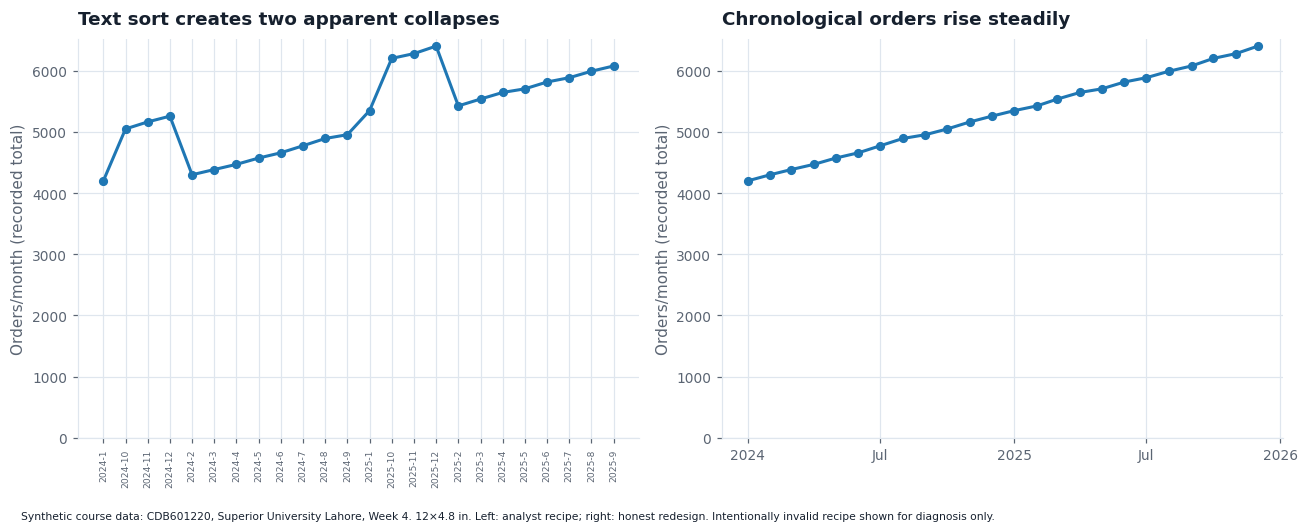

In [6]:
r=read('case01_orders_stringdate.csv');d=temporal('case01_orders_stringdate.csv','month','MS','%Y-%m');bad=r.sort_values('month');drops=bad.orders.diff();assert sorted(drops[drops<0])==[-978,-958]
fig,axs=pair();axs[0].plot(bad.month,bad.orders,marker='o');axs[0].tick_params(axis='x',rotation=90,labelsize=6);axs[0].set(ylim=(0,None),title='Text sort creates two apparent collapses',ylabel='Orders/month (recorded total)');axs[1].plot(d.index,d.orders,marker='o');axs[1].set(ylim=(0,None),title='Chronological orders rise steadily',ylabel='Orders/month (recorded total)');dateaxis(axs[1])
record(1,'Lexicographic dates','Orders appear to collapse annually.','Not a truncated y-axis: both start at zero; branch is constant across all 24 rows.',f'Text order puts October–December between January and February in each year; December→February causes drops {drops[drops<0].tolist()}. Chronological minimum monthly change is {d.orders.diff().min():.0f}; first→last {d.orders.iloc[0]}→{d.orders.iloc[-1]}.','Parse YYYY-M explicitly, sort DatetimeIndex and use a calendar axis.',fig)

case02_shop_closed.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 69, 'n_duplicated': 0, 'n_missing': 21, 'missing_dates': ['2025-02-03 00:00:00', '2025-02-04 00:00:00', '2025-02-05 00:00:00', '2025-02-06 00:00:00', '2025-02-07 00:00:00', '2025-02-08 00:00:00', '2025-02-09 00:00:00', '2025-02-10 00:00:00', '2025-02-11 00:00:00', '2025-02-12 00:00:00', '2025-02-13 00:00:00', '2025-02-14 00:00:00'], 'span': ('2025-01-01 00:00:00', '2025-03-31 00:00:00'), 'partial_tail': False, 'tail_period': '2025-03', 'tail_count': 31}
Trading totals by calendar month: {Timestamp('2025-01-01 00:00:00'): 6076.0, Timestamp('2025-02-01 00:00:00'): 1650.0, Timestamp('2025-03-01 00:00:00'): 7834.0}

CASE 2 Time compression 
Conclusion: A 22% endpoint rise appears to be steady quarter-wide growth. 
Decoy: The endpoint arithmetic is true: 22.22%; it does not establish a regular daily trend. 
Mechanism: 69 observations span 90 days; 21 absent days vanish on a row-number axis. Monthly record

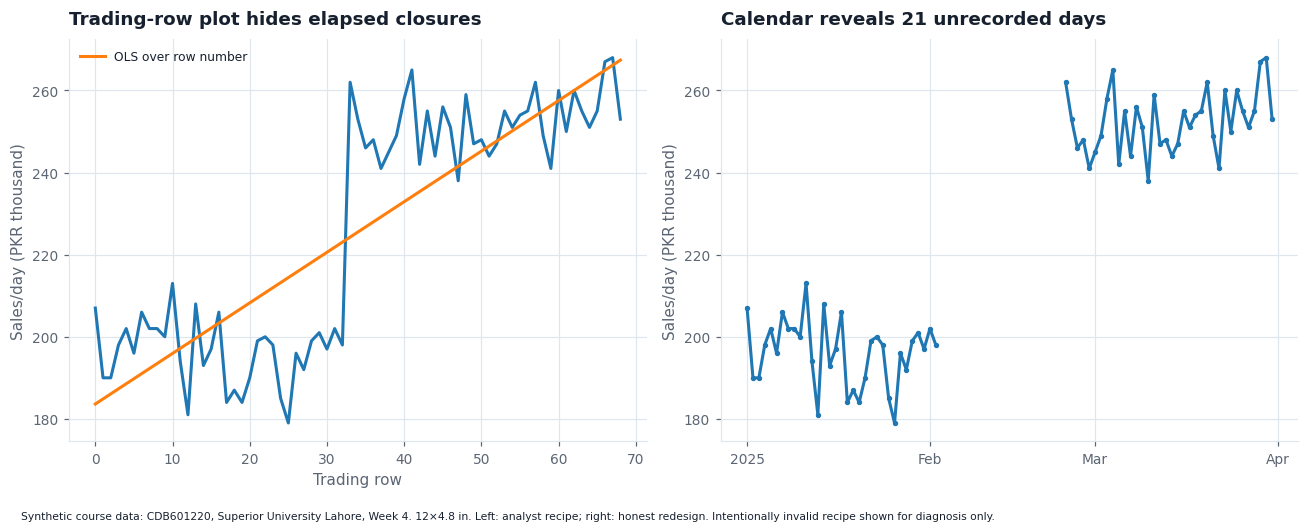

In [7]:
d=temporal('case02_shop_closed.csv','date','D');s=d.sales_pkr_k;full=tslib.reindex_full(s,'D');fig,axs=pair();x=np.arange(len(s));axs[0].plot(x,s);axs[0].plot(x,np.polyval(np.polyfit(x,s,1),x),label='OLS over row number');axs[0].set(title='Trading-row plot hides elapsed closures',xlabel='Trading row',ylabel='Sales/day (PKR thousand)');axs[0].legend(fontsize=8);axs[1].plot(full,marker='.',label='Observed trading sales');axs[1].set(title='Calendar reveals 21 unrecorded days',ylabel='Sales/day (PKR thousand)');dateaxis(axs[1]);months=full.resample('MS').sum(min_count=1);print('Trading totals by calendar month:',months.to_dict())
record(2,'Time compression','A 22% endpoint rise appears to be steady quarter-wide growth.',f'The endpoint arithmetic is true: {(s.iloc[-1]/s.iloc[0]-1)*100:.2f}%; it does not establish a regular daily trend.',f'{len(s)} observations span {len(full)} days; {full.isna().sum()} absent days vanish on a row-number axis. Monthly recorded totals: {months.to_dict()}.','Use dates and preserve gaps; do not impute zero without verified closure records.',fig)

case03_bandwidth_levels.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 1237, 'n_duplicated': 0, 'n_missing': 227, 'missing_dates': ['2025-06-01 12:00:00', '2025-06-01 13:00:00', '2025-06-01 14:00:00', '2025-06-01 15:00:00', '2025-06-01 16:00:00', '2025-06-01 17:00:00', '2025-06-01 18:00:00', '2025-06-01 19:00:00', '2025-06-01 20:00:00', '2025-06-01 21:00:00', '2025-06-02 13:00:00', '2025-06-02 14:00:00'], 'span': ('2025-06-01 00:00:00', '2025-07-31 23:00:00'), 'partial_tail': False, 'tail_period': '2025-07-31', 'tail_count': 24}
       wrong_sum  mean_level    samples
ts                                     
6    8782.433333  535.887393  16.433333
7   12543.129032  522.630376  24.000000

CASE 3 A level summed over unequal coverage 
Conclusion: Peak demand seems to jump in July. 
Decoy: The axis is zero-based; bytes served is a flow, but concurrent users is a stock/level. 
Mechanism: June/July daily statistics: {'wrong_sum': {6: 8782.433333333332, 7: 12543.1290322580

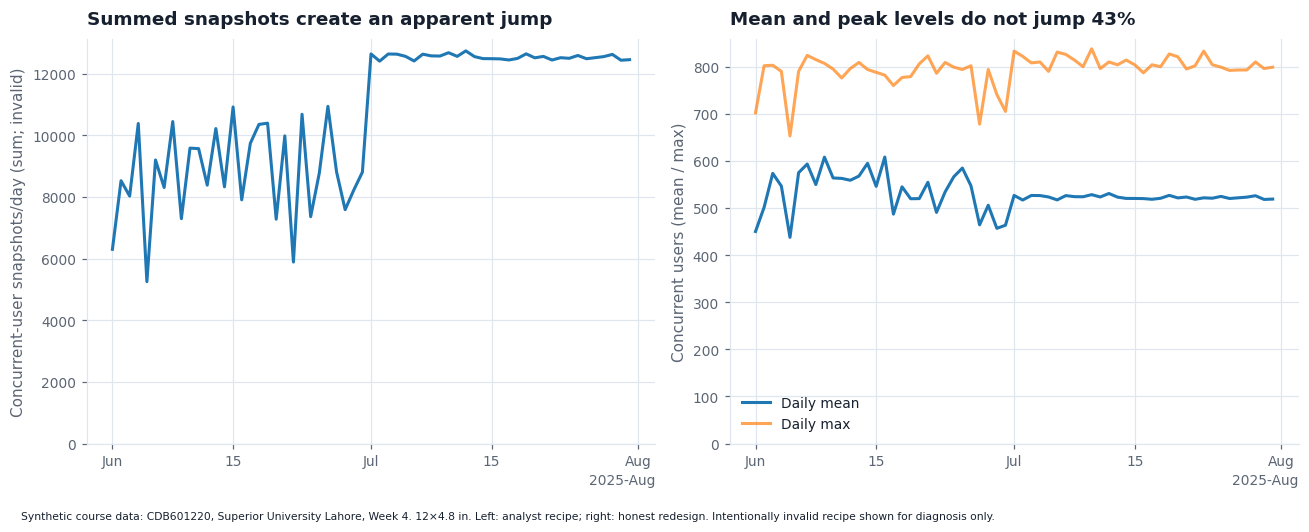

In [8]:
d=temporal('case03_bandwidth_levels.csv','ts','h');wrong=d.concurrent_users.resample('D').sum();mean=d.concurrent_users.resample('D').mean();peak=d.concurrent_users.resample('D').max();n=d.concurrent_users.resample('D').count();fig,axs=pair();axs[0].plot(wrong);axs[0].set(ylim=(0,None),title='Summed snapshots create an apparent jump',ylabel='Concurrent-user snapshots/day (sum; invalid)');axs[1].plot(mean,label='Daily mean');axs[1].plot(peak,label='Daily max',alpha=.7);axs[1].set(ylim=(0,None),title='Mean and peak levels do not jump 43%',ylabel='Concurrent users (mean / max)');axs[1].legend();[dateaxis(a) for a in axs]
stats=pd.DataFrame({'wrong_sum':wrong,'mean_level':mean,'samples':n}).groupby(lambda x:x.month).mean();print(stats)
record(3,'A level summed over unequal coverage','Peak demand seems to jump in July.','The axis is zero-based; bytes served is a flow, but concurrent users is a stock/level.',f'June/July daily statistics: {stats.to_dict()}. Summing more snapshots scales with observation count, not simultaneous demand.','Show daily mean and maximum level; report observation counts. Use sum only for bytes served.',fig)

case04_intervention_lag.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 214, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2025-05-01 00:00:00', '2025-11-30 00:00:00'), 'partial_tail': False, 'tail_period': '2025-11', 'tail_count': 30}

CASE 4 Filter phase lag 
Conclusion: The checkout change appears to start working on 7 September. 
Decoy: This is not evidence of a second intervention; a centered filter uses future data and cannot be deployed live. 
Mechanism: Trailing minimum 2025-09-07, centered minimum 2025-08-23, lag 15 days = half-window 15. 
Redesign: Retrospectively show centered mean with raw data; label trailing lag on live charts. No causal attribution from timing alone.


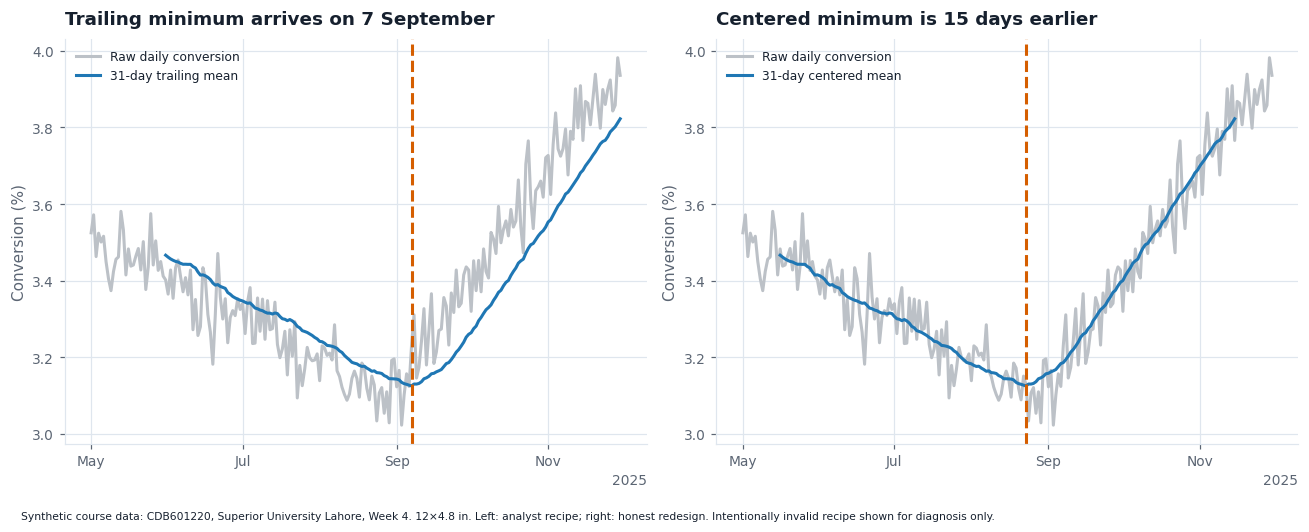

In [9]:
d=temporal('case04_intervention_lag.csv','date','D');s=d.conversion_pct;t=s.rolling(31).mean();c=s.rolling(31,center=True).mean();lg=tslib.lag_at_turn(s,31);assert str(t.idxmin().date())=='2025-09-07';fig,axs=pair()
for ax in axs:ax.plot(s,color='#bcc1c7',label='Raw daily conversion');ax.set(ylabel='Conversion (%)');dateaxis(ax)
axs[0].plot(t,label='31-day trailing mean');axs[0].axvline(t.idxmin(),color=COL[1],ls='--');axs[0].set_title('Trailing minimum arrives on 7 September');axs[1].plot(c,label='31-day centered mean');axs[1].axvline(c.idxmin(),color=COL[1],ls='--');axs[1].set_title('Centered minimum is 15 days earlier');[a.legend(fontsize=8) for a in axs]
record(4,'Filter phase lag','The checkout change appears to start working on 7 September.','This is not evidence of a second intervention; a centered filter uses future data and cannot be deployed live.',f'Trailing minimum {lg["trailing_turn"].date()}, centered minimum {lg["centred_turn"].date()}, lag {lg["lag_periods"]} days = half-window {lg["half_window"]}.','Retrospectively show centered mean with raw data; label trailing lag on live charts. No causal attribution from timing alone.',fig)

case05_revenue_window.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 36, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2023-01-01 00:00:00', '2025-12-01 00:00:00'), 'partial_tail': False, 'tail_period': '2025', 'tail_count': 12}

CASE 5 Seasonal window selection 
Conclusion: Revenue seems to be persistently deteriorating. 
Decoy: The recipe explicitly starts the axis at zero; there are 36 complete months, not a seven-month source file. 
Mechanism: Selected seven points fall 158.8→92.2 (-41.9%). Same-month 2025 vs 2024 changes range 5.9% to 13.3%. 
Redesign: Show all 36 months and compare matching months across years; a seasonal downswing is not a long-run decline.


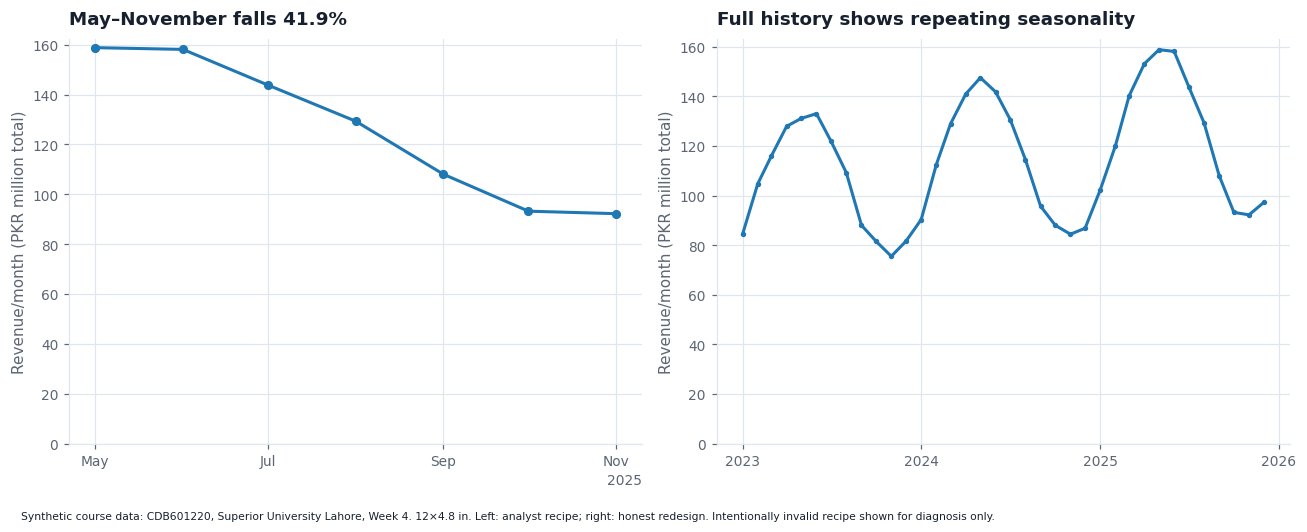

In [10]:
d=temporal('case05_revenue_window.csv','month','MS');s=d.revenue_pkr_m;cut=s.loc['2025-05':'2025-11'];fig,axs=pair();axs[0].plot(cut,marker='o');axs[0].set(ylim=(0,None),title='May–November falls 41.9%',ylabel='Revenue/month (PKR million total)');axs[1].plot(s,marker='.');axs[1].set(ylim=(0,None),title='Full history shows repeating seasonality',ylabel='Revenue/month (PKR million total)');[dateaxis(a) for a in axs];yoy=(s.loc['2025'].to_numpy()/s.loc['2024'].to_numpy()-1)*100
record(5,'Seasonal window selection','Revenue seems to be persistently deteriorating.','The recipe explicitly starts the axis at zero; there are 36 complete months, not a seven-month source file.',f'Selected seven points fall {cut.iloc[0]}→{cut.iloc[-1]} ({(cut.iloc[-1]/cut.iloc[0]-1)*100:.1f}%). Same-month 2025 vs 2024 changes range {yoy.min():.1f}% to {yoy.max():.1f}%.','Show all 36 months and compare matching months across years; a seasonal downswing is not a long-run decline.',fig)

case06_monthly_partial.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 284, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2025-01-01 00:00:00', '2025-10-11 00:00:00'), 'partial_tail': True, 'tail_period': '2025-10', 'tail_count': 11}

CASE 6 Unequal exposure in a partial month 
Conclusion: Orders appear to collapse in October. 
Decoy: Monthly sum is correct for a flow and the bars start at zero; the periods are not equally complete. 
Mechanism: September 10805 in 30 days (360.2/day); October 4041 in 11 days (367.4/day), extracted 2025-10-11. 
Redesign: Retain zero baseline, label partial exposure, and compare per-observed-day rates instead of unequal monthly totals.


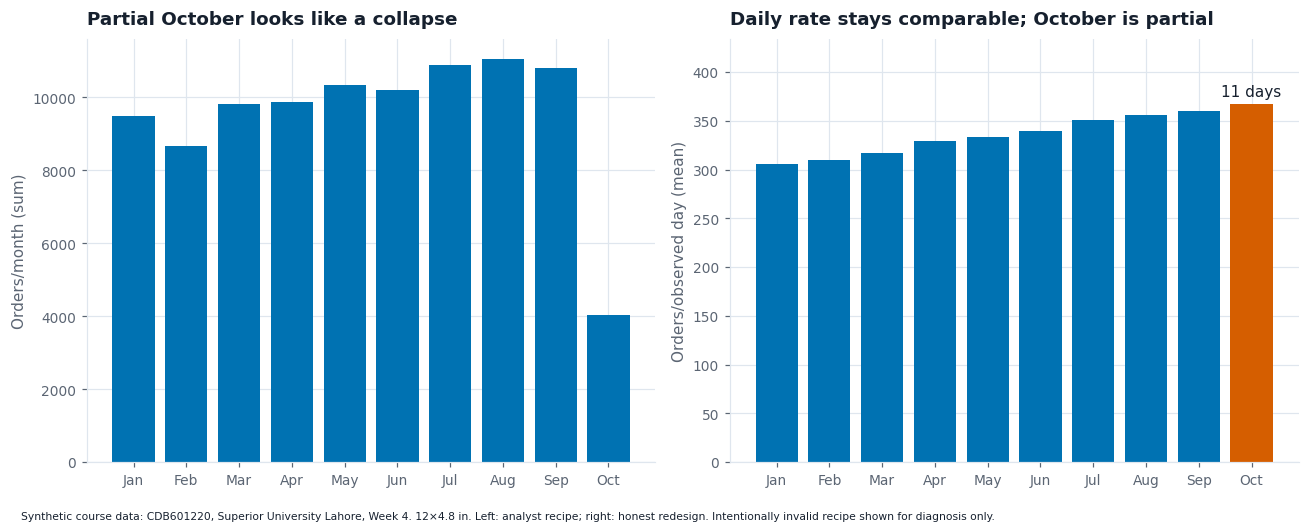

In [11]:
d=temporal('case06_monthly_partial.csv','date','D');total=d.orders.resample('MS').sum();avg=d.orders.resample('MS').mean();counts=d.orders.resample('MS').count();assert total.iloc[-2]==10805 and total.iloc[-1]==4041;fig,axs=pair();labels=total.index.strftime('%b');axs[0].bar(labels,total,color=COL[0]);axs[0].set(title='Partial October looks like a collapse',ylabel='Orders/month (sum)');axs[1].bar(labels,avg,color=[COL[0]]*9+[COL[1]]);axs[1].set(title='Daily rate stays comparable; October is partial',ylabel='Orders/observed day (mean)');axs[1].text(9,avg.iloc[-1]+8,f'{counts.iloc[-1]} days',ha='center');axs[1].set_ylim(0,avg.max()*1.18)
record(6,'Unequal exposure in a partial month','Orders appear to collapse in October.','Monthly sum is correct for a flow and the bars start at zero; the periods are not equally complete.',f'September {total.iloc[-2]} in {counts.iloc[-2]} days ({avg.iloc[-2]:.1f}/day); October {total.iloc[-1]} in {counts.iloc[-1]} days ({avg.iloc[-1]:.1f}/day), extracted {d.index.max().date()}.','Retain zero baseline, label partial exposure, and compare per-observed-day rates instead of unequal monthly totals.',fig)

case07_stacked_products.csv before sorting: {'dtype_ok': True, 'monotonic': True, 'n_rows': 36, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2023-01-01 00:00:00', '2025-12-01 00:00:00'), 'partial_tail': False, 'tail_period': '2025', 'tail_count': 12}

CASE 7 Volatility transferred through a stack baseline 
Conclusion: The upper envelope seems to show erratic product D. 
Decoy: The stack is legal: products are exclusive, exhaustive and positive; the issue is comparison, not arithmetic. 
Mechanism: Total envelope 548.3–708.7; D range 94.0–106.3, SD 3.55; lower three baseline SD 39.27. 
Redesign: Keep the legal composition stack and add an unstacked D series beside it. Band thickness, not top boundary, is D.


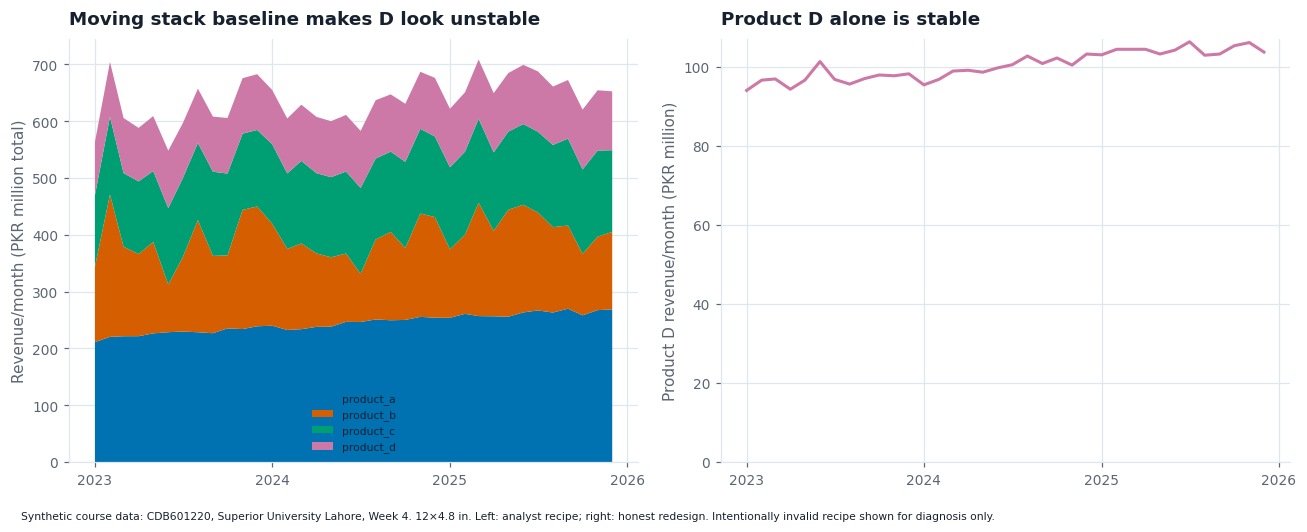

In [12]:
d=temporal('case07_stacked_products.csv','month','MS');s=d.filter(like='product');fig,axs=pair();axs[0].stackplot(s.index,*[s[x] for x in s],labels=s.columns,colors=COL);axs[0].legend(fontsize=7);axs[0].set(title='Moving stack baseline makes D look unstable',ylabel='Revenue/month (PKR million total)');axs[1].plot(s.product_d,label='Product D',color=COL[3]);axs[1].set(ylim=(0,None),title='Product D alone is stable',ylabel='Product D revenue/month (PKR million)');[dateaxis(a) for a in axs]
record(7,'Volatility transferred through a stack baseline','The upper envelope seems to show erratic product D.','The stack is legal: products are exclusive, exhaustive and positive; the issue is comparison, not arithmetic.',f'Total envelope {s.sum(axis=1).min():.1f}–{s.sum(axis=1).max():.1f}; D range {s.product_d.min():.1f}–{s.product_d.max():.1f}, SD {s.product_d.std():.2f}; lower three baseline SD {s.iloc[:,:3].sum(axis=1).std():.2f}.','Keep the legal composition stack and add an unstacked D series beside it. Band thickness, not top boundary, is D.',fig)

{'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}

CASE 8 Non-exclusive denominator 
Conclusion: Search appears to cause 43% of customers. 
Decoy: Each reach percentage is arithmetically correct with 4,000 customers as denominator; neither rounding nor a bad axis explains the sum. 
Mechanism: Shares {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58} sum to 131.0%; 1105 customers have multiple touches. Pie area for search is 32.54%, not 42.6%. 
Redesign: Separate reach bars use a common customer denominator; labels explicitly say overlap, and touching a channel is not causal attribution.


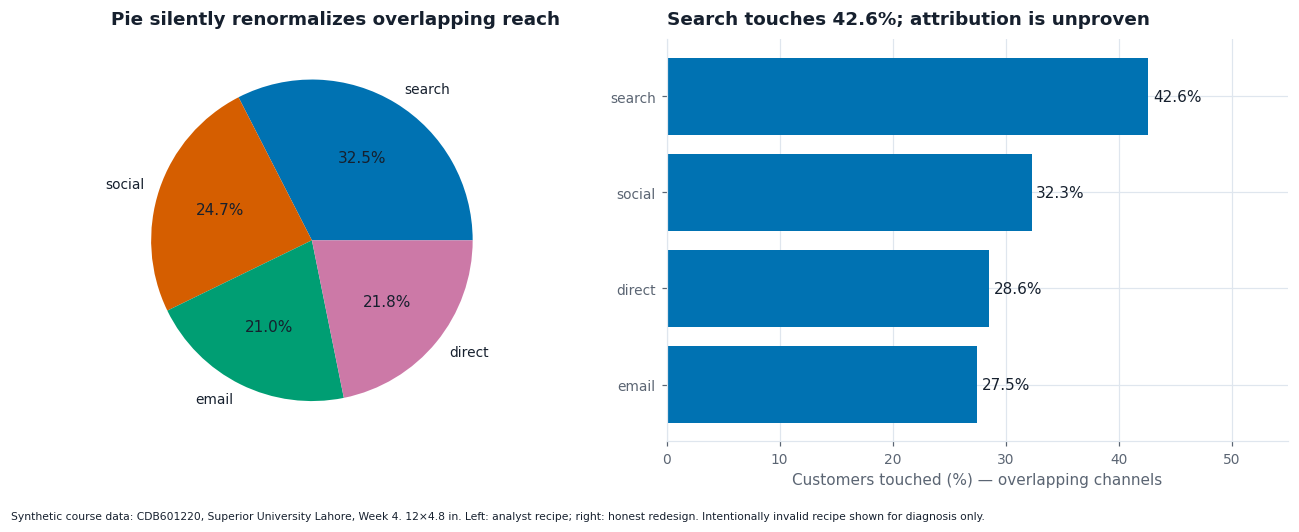

In [13]:
d=read('case08_channel_attrib.csv');flags=d.filter(like='touch_').columns;ex=tslib.exclusivity_check(d,flags);shares=d[flags].mean()*100;print(ex);fig,axs=pair();axs[0].pie(shares,labels=[x.replace('touch_','') for x in flags],autopct='%1.1f%%',colors=COL);axs[0].set_title('Pie silently renormalizes overlapping reach');ss=shares.sort_values();axs[1].barh([x.replace('touch_','') for x in ss.index],ss,color=COL[0]);axs[1].bar_label(axs[1].containers[0],fmt='%.1f%%',padding=3);axs[1].set(xlim=(0,55),title='Search touches 42.6%; attribution is unproven',xlabel='Customers touched (%) — overlapping channels')
record(8,'Non-exclusive denominator','Search appears to cause 43% of customers.','Each reach percentage is arithmetically correct with 4,000 customers as denominator; neither rounding nor a bad axis explains the sum.',f'Shares {shares.round(2).to_dict()} sum to {shares.sum():.1f}%; {ex["n_multi"]} customers have multiple touches. Pie area for search is {shares.iloc[0]/shares.sum()*100:.2f}%, not 42.6%.','Separate reach bars use a common customer denominator; labels explicitly say overlap, and touching a channel is not causal attribution.',fig)

case09 audit {'dtype_ok': True, 'monotonic': True, 'n_rows': 8, 'n_duplicated': 0, 'n_missing': 0, 'missing_dates': [], 'span': ('2024-01-01 00:00:00', '2025-10-01 00:00:00'), 'partial_tail': False, 'tail_period': '2025', 'tail_count': 4}

CASE 9 Rising fraction of a shrinking denominator 
Conclusion: A record share suggests premium is growing. 
Decoy: The 24%→38% share is true, exclusive and meaningful for mix; it is incomplete for performance. 
Mechanism: Total 1000.0→600.0; premium 240.0→228.0, a -5.0% change. Denominator shrinks faster. 
Redesign: Keep the share chart and add absolute premium and total revenue on a separate shared-unit panel, never a dual axis.


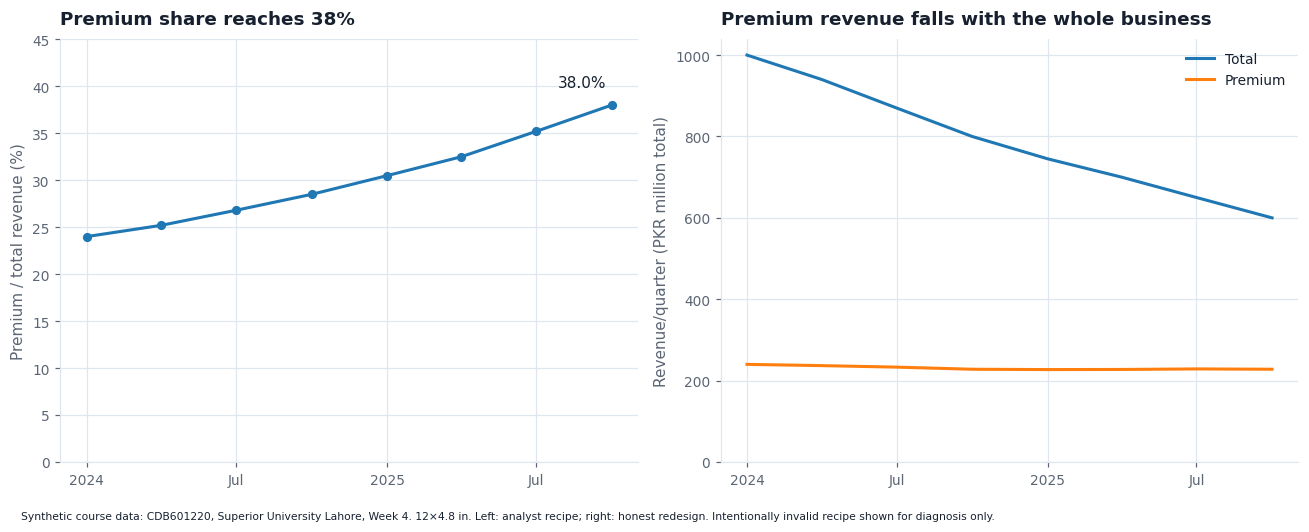

In [14]:
d=read('case09_premium_share.csv');d.index=pd.PeriodIndex(d.quarter,freq='Q').to_timestamp();print('case09 audit',tslib.audit_index(d,'QS'));p=d.premium_revenue_pkr_m/d.total_revenue_pkr_m*100;fig,axs=pair();axs[0].plot(d.index,p,marker='o');axs[0].set(ylim=(0,45),title='Premium share reaches 38%',ylabel='Premium / total revenue (%)');axs[0].annotate('38.0%',(d.index[-1],p.iloc[-1]),xytext=(-35,12),textcoords='offset points');axs[1].plot(d.index,d.total_revenue_pkr_m,label='Total');axs[1].plot(d.index,d.premium_revenue_pkr_m,label='Premium');axs[1].set(ylim=(0,None),title='Premium revenue falls with the whole business',ylabel='Revenue/quarter (PKR million total)');axs[1].legend();[dateaxis(a) for a in axs]
record(9,'Rising fraction of a shrinking denominator','A record share suggests premium is growing.','The 24%→38% share is true, exclusive and meaningful for mix; it is incomplete for performance.',f'Total {d.total_revenue_pkr_m.iloc[0]:.1f}→{d.total_revenue_pkr_m.iloc[-1]:.1f}; premium {d.premium_revenue_pkr_m.iloc[0]:.1f}→{d.premium_revenue_pkr_m.iloc[-1]:.1f}, a {(d.premium_revenue_pkr_m.iloc[-1]/d.premium_revenue_pkr_m.iloc[0]-1)*100:.1f}% change. Denominator shrinks faster.','Keep the share chart and add absolute premium and total revenue on a separate shared-unit panel, never a dual axis.',fig)
(OUT/'partA_diagnoses.json').write_text(json.dumps(diagnoses,indent=2,ensure_ascii=False))

## Part B — Smoothing and framing sensitivity

All statistics use the same regular calendar as Part D. The decomposition-only copy fills remaining daily gaps and explicitly marks them. No extra annual history is invented.

In [15]:
from common import *
from statsmodels.tsa.seasonal import seasonal_decompose
_,h,daily,_,_=clean_sessions(False)
report=tslib.window_report(daily,(7,28,91));print(report.to_string(index=False));report.to_csv(OUT/'window_report.csv',index=False)
print('Variation removed is reduction in standard deviation, NOT variance. 7 days cancels the weekly cycle; 28 averages four weeks; 91 averages thirteen weeks and attenuates slower seasonal movement. Select 7 days for Monday monitoring.')
print('Toolkit caveat: its min_periods=window//2 allows partial edge windows, so reported periods_lost_each_end is nominal support loss, not actual missing output. Dashboard uses strict full windows.')
for w in (7,28,91):
    strict=daily.rolling(w,center=True,min_periods=w).mean()
    print(w,'strict leading/trailing support losses:',w//2,(w-1)//2,'missing output total incl gaps:',strict.isna().sum())

 window   raw_sd  smoothed_sd  variation_removed_pct  periods_lost_each_end
      7 6820.057    4667.8459                   31.6                      3
     28 6820.057    4448.4975                   34.8                     14
     91 6820.057    4168.8358                   38.9                     45
Variation removed is reduction in standard deviation, NOT variance. 7 days cancels the weekly cycle; 28 averages four weeks; 91 averages thirteen weeks and attenuates slower seasonal movement. Select 7 days for Monday monitoring.
Toolkit caveat: its min_periods=window//2 allows partial edge windows, so reported periods_lost_each_end is nominal support loss, not actual missing output. Dashboard uses strict full windows.
7 strict leading/trailing support losses: 3 3 missing output total incl gaps: 86
28 strict leading/trailing support losses: 14 13 missing output total incl gaps: 298
91 strict leading/trailing support losses: 45 45 missing output total incl gaps: 518


Black Friday raw: 113710.0
14-day centered mean: 33468.17857142857 median: 24780.5 EWMA span 14: 38029.4130322111
EWMA is causal, not centered; alpha=2/15, adjust=False, ignore_na=True. Live monitoring: EWMA alongside raw spike. Retrospective typical-day quarterly summary: centered median with raw event retained. Median is not a substitute for a revenue/session total.


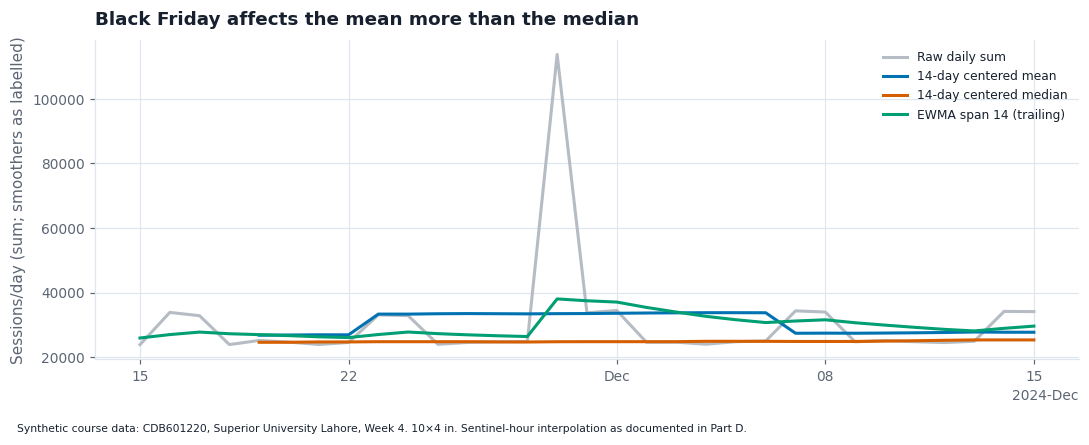

In [16]:
t=pd.Timestamp('2024-11-29');means=daily.rolling(14,center=True,min_periods=14).mean();medians=daily.rolling(14,center=True,min_periods=14).median();ewma=daily.ewm(span=14,adjust=False,ignore_na=True).mean()
print('Black Friday raw:',daily.loc[t]);print('14-day centered mean:',means.loc[t],'median:',medians.loc[t],'EWMA span 14:',ewma.loc[t])
print('EWMA is causal, not centered; alpha=2/15, adjust=False, ignore_na=True. Live monitoring: EWMA alongside raw spike. Retrospective typical-day quarterly summary: centered median with raw event retained. Median is not a substitute for a revenue/session total.')
fig,ax=plt.subplots(figsize=(10,4));sel=slice('2024-11-15','2024-12-15')
for s,label,color in [(daily,'Raw daily sum','#b6bcc3'),(means,'14-day centered mean',COL[0]),(medians,'14-day centered median',COL[1]),(ewma,'EWMA span 14 (trailing)',COL[2])]:ax.plot(s.loc[sel],label=label,color=color)
ax.set(title='Black Friday affects the mean more than the median',ylabel='Sessions/day (sum; smoothers as labelled)');ax.legend(fontsize=8);dateaxis(ax);finish(fig,'partB_spike.png','10×4 in. Sentinel-hour interpolation as documented in Part D.')

Decomposition-only estimated days: 14 ; boundary fill: 1
Weekly peak-to-trough amplitude: 7528.177329011231 sessions/day; largest absolute residual: 2024-11-29 00:00:00 value: 74556.068955579
Annual decomposition cannot be estimated: x must have 2 complete cycles requires 730 observations. x only has 518 observation(s)
Only 518 days are available, below 730 required for two annual cycles; no annual result is fabricated. With sufficient history, repeating annual variation could move from residual into seasonal.


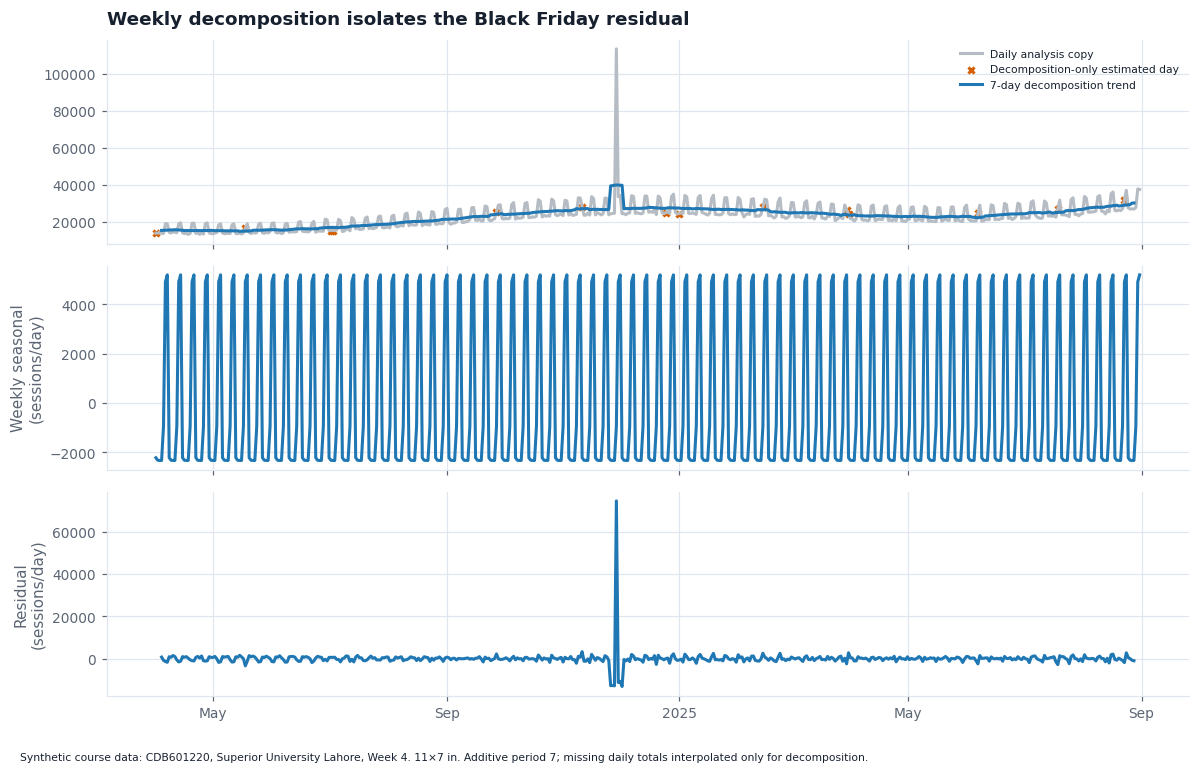

In [17]:
# seasonal_decompose forbids NaN. Interpolate on a separate analysis copy, never silently in raw chart.
analysis=daily.interpolate('time',limit_direction='both');imputed=daily.isna()
print('Decomposition-only estimated days:',int(imputed.sum()),'; boundary fill:',int(daily.iloc[[0,-1]].isna().sum()))
dec=seasonal_decompose(analysis,model='additive',period=7)
amp=dec.seasonal.max()-dec.seasonal.min();resdate=dec.resid.abs().idxmax()
print('Weekly peak-to-trough amplitude:',amp,'sessions/day; largest absolute residual:',resdate,'value:',dec.resid.loc[resdate])
try:
    annual=seasonal_decompose(analysis,model='additive',period=365)
except ValueError as e:
    print('Annual decomposition cannot be estimated:',e)
print('Only 518 days are available, below 730 required for two annual cycles; no annual result is fabricated. With sufficient history, repeating annual variation could move from residual into seasonal.')
fig,axs=plt.subplots(3,1,figsize=(11,7),sharex=True)
axs[0].plot(analysis,color='#b6bcc3',label='Daily analysis copy');axs[0].scatter(analysis.index[imputed],analysis[imputed],s=16,marker='x',color=COL[1],label='Decomposition-only estimated day');axs[0].plot(dec.trend,label='7-day decomposition trend');axs[0].legend(fontsize=7);axs[0].set_title('Weekly decomposition isolates the Black Friday residual')
axs[1].plot(dec.seasonal);axs[1].set_ylabel('Weekly seasonal\n(sessions/day)');axs[2].plot(dec.resid);axs[2].set_ylabel('Residual\n(sessions/day)');dateaxis(axs[2]);finish(fig,'partB_decomposition.png','11×7 in. Additive period 7; missing daily totals interpolated only for decomposition.')

In [18]:
lag=tslib.lag_at_turn(daily,31);print('31-day turning-point lag:',lag)
print('The minimum is compared on the same regular calendar with strict full-window support. A live dashboard must use trailing estimates and say: 31-day trailing mean, historical smoothing delays turns by about 15 days; newest value uses no future data.')

31-day turning-point lag: {'window': 31, 'trailing_turn': Timestamp('2024-05-16 00:00:00'), 'centred_turn': Timestamp('2024-05-01 00:00:00'), 'lag_periods': 15, 'half_window': 15}
The minimum is compared on the same regular calendar with strict full-window support. A live dashboard must use trailing estimates and say: 31-day trailing mean, historical smoothing delays turns by about 15 days; newest value uses no future data.


     start        end  window_days  slope_sessions_per_day2 direction
2024-04-01 2025-08-31            7                21.186628    rising
2024-04-01 2025-08-31           14                21.153674    rising
2024-04-01 2025-08-31           28                21.118666    rising
2024-04-01 2025-08-31           56                20.911596    rising
2024-04-01 2025-08-31           91                20.483547    rising
2024-05-01 2025-08-31            7                19.210324    rising
2024-05-01 2025-08-31           14                19.317471    rising
2024-05-01 2025-08-31           28                19.277930    rising
2024-05-01 2025-08-31           56                18.889976    rising
2024-05-01 2025-08-31           91                18.299560    rising
2024-06-01 2025-08-31            7                15.568648    rising
2024-06-01 2025-08-31           14                15.658919    rising
2024-06-01 2025-08-31           28                15.583332    rising
2024-06-01 2025-08-3

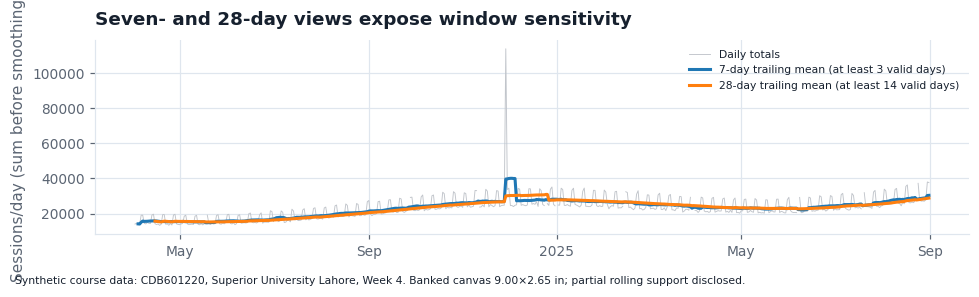

In [19]:
# Operational definition: 12 consecutive start months beginning April 2024,
# a fixed common end date, and each stated centered rolling window. No choice is hidden.
rows=[]
for start in pd.date_range(daily.index.min(),periods=12,freq='MS'):
    for w in (7,14,28,56,91):
        s=daily.loc[start:].rolling(w,center=True,min_periods=max(2,w//2)).mean().dropna()
        slope=np.polyfit((s.index-s.index[0]).days,s,1)[0]
        rows.append({'start':start.date(),'end':daily.index.max().date(),'window_days':w,'slope_sessions_per_day2':slope,'direction':'rising' if slope>0 else 'falling' if slope<0 else 'flat'})
sensitivity=pd.DataFrame(rows);print(sensitivity.to_string(index=False));print('Direction counts:',sensitivity.direction.value_counts().to_dict());sensitivity.to_csv(OUT/'window_sensitivity_60.csv',index=False)
print('The brief does not specify a year, end date or fit convention; the above definition makes these 60 results reproducible. A cherry-picked interval has no unique reference effect across periods; a scalar Lie Factor would require a defensible common estimand and baseline. Report every window, dates and slopes, alongside full-history data instead.')
valid=daily.dropna();bank=tslib.banked_figsize(valid.to_numpy(),x=(valid.index-valid.index[0]).days.to_numpy());print('Banked figsize:',bank,'width/height:',bank[0]/bank[1],'; clipping in toolkit means not necessarily exactly 45 degrees.')
fig,ax=plt.subplots(figsize=bank);ax.plot(daily,color='#c1c5cb',lw=.6,label='Daily totals');
for w in (7,28):ax.plot(daily.rolling(w,min_periods=max(2,w//2)).mean(),label=f'{w}-day trailing mean (at least {max(2,w//2)} valid days)')
ax.set(title='Seven- and 28-day views expose window sensitivity',ylabel='Sessions/day (sum before smoothing)');ax.legend(fontsize=7);dateaxis(ax);finish(fig,'partB_window_appendix.png',f'Banked canvas {bank[0]:.2f}×{bank[1]:.2f} in; partial rolling support disclosed.')

## Part C — Share legality and reader task

The stimuli are prepared below. Automated execution cannot supply a real reader; use the final interactive cell to collect actual observations.

In [20]:
from common import *
import time
from IPython.display import display, Image, clear_output
shares=read('shares_eight.csv');touch=read('case08_channel_attrib.csv');flags=touch.filter(like='touch_').columns
check=tslib.exclusivity_check(touch,flags);print('Touch flags:',check)
assert not check['exclusive']
assert shares.slice.is_unique and shares.subcategory.is_unique and (shares.share_pct>=0).all()
assert abs(shares.share_pct.sum()-100)<1e-6
# One-hot membership of the eight documented disjoint subcategories.
print('Eight category membership:',tslib.exclusivity_check(pd.get_dummies(shares.subcategory),shares.subcategory))
p=read('case09_premium_share.csv').query("quarter=='2025Q4'").iloc[0];parts=pd.Series({'Premium':p.premium_revenue_pkr_m,'Other':p.total_revenue_pkr_m-p.premium_revenue_pkr_m});pct=parts/parts.sum()*100
assert (parts>=0).all() and abs(pct.sum()-100)<1e-6
print('2025Q4:',parts.to_dict(),pct.to_dict())
print('VERDICTS: Touches: no pie (overlap); separate reach bars valid; neither chart proves causation. Eight shares: pie legal for mix, sorted bars preferred for exact ranking. Premium/other: pie or bars legal for revenue composition; neither alone answers absolute growth. Exclusivity of revenue partitions follows their definition, not their summing to 100 alone.')

Touch flags: {'n': 4000, 'shares_pct': {'touch_search': 42.62, 'touch_social': 32.3, 'touch_email': 27.48, 'touch_direct': 28.58}, 'sum_pct': 130.98, 'exclusive': False, 'n_multi': 1105, 'pct_multi': 27.62, 'n_zero': 0}
Eight category membership: {'n': 8, 'shares_pct': {'Phones': 12.5, 'Laptops': 12.5, 'Audio': 12.5, 'Wearables': 12.5, 'Cameras': 12.5, 'Drones': 12.5, 'Footwear': 12.5, 'Accessories': 12.5}, 'sum_pct': 100.0, 'exclusive': True, 'n_multi': 0, 'pct_multi': 0.0, 'n_zero': 0}
2025Q4: {'Premium': 228.0, 'Other': 372.0} {'Premium': 38.0, 'Other': 62.0}
VERDICTS: Touches: no pie (overlap); separate reach bars valid; neither chart proves causation. Eight shares: pie legal for mix, sorted bars preferred for exact ranking. Premium/other: pie or bars legal for revenue composition; neither alone answers absolute growth. Exclusivity of revenue partitions follows their definition, not their summing to 100 alone.


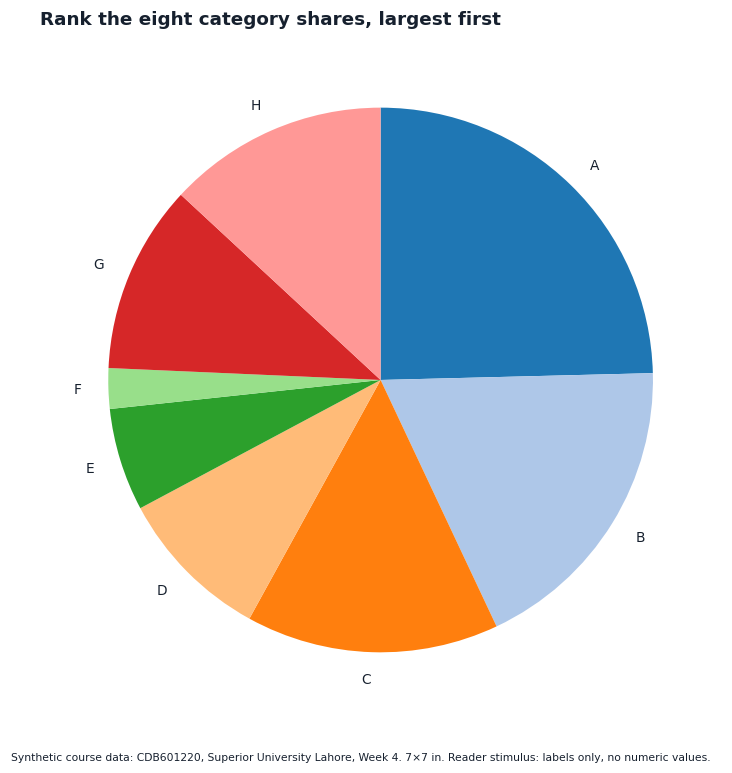

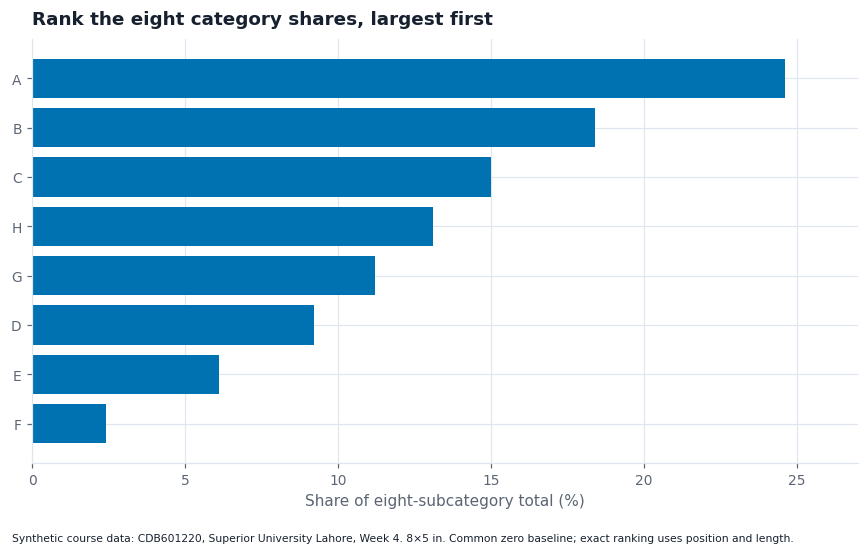

In [21]:
fig,ax=plt.subplots(figsize=(7,7));ax.pie(shares.share_pct,labels=shares.slice,startangle=90,counterclock=False,colors=plt.get_cmap('tab20').colors[:8]);ax.set_title('Rank the eight category shares, largest first');finish(fig,'partC_pie_stimulus.png','7×7 in. Reader stimulus: labels only, no numeric values.')
ordered=shares.sort_values('share_pct');fig,ax=plt.subplots(figsize=(8,5));ax.barh(ordered.slice,ordered.share_pct,color=COL[0]);ax.set(title='Rank the eight category shares, largest first',xlabel='Share of eight-subcategory total (%)',xlim=(0,27));finish(fig,'partC_bar_stimulus.png','8×5 in. Common zero baseline; exact ranking uses position and length.')

In [22]:
true_order=shares.sort_values('share_pct',ascending=False).slice.tolist()
def score_order(order):
    answer=[x for x in order.upper() if x in 'ABCDEFGH']
    if len(answer)!=8 or set(answer)!=set('ABCDEFGH'):raise ValueError('Enter each letter A–H exactly once.')
    positions=[i+1 for i,(a,b) in enumerate(zip(answer,true_order)) if a!=b]
    return ''.join(answer),len(positions),positions

def run_reader_experiment():
    reader=input('Anonymous reader ID (do not use a full name): ').strip()
    rows=[]
    for stimulus in ['pie','bar']:
        clear_output(wait=True)
        input('Press Enter when the reader is ready. Do not reveal the true order.')
        clear_output(wait=True)
        display(Image(filename=str(OUT/f'partC_{stimulus}_stimulus.png')))
        start=time.perf_counter();order=input('Largest to smallest (all A–H, once each): ');seconds=time.perf_counter()-start
        normalized,wrong,positions=score_order(order)
        rows.append(dict(reader=reader,stimulus=stimulus,order=normalized,seconds=seconds,wrong_count=wrong,wrong_positions=' '.join(map(str,positions)),status='observed'))
    result=pd.DataFrame(rows);result.to_csv(OUT/'pie_ranking_results.csv',index=False)
    clear_output(wait=True);display(result)
    print('True order:',''.join(true_order))
    for row in rows:print(row['stimulus'],'wrong positions:',row['wrong_positions'] or 'none','; top two and bottom one correct:',not(set(map(int,row['wrong_positions'].split())) & {1,2,8}))
    print('This is one reader, pie first and bars second: practice, typing time and order effects limit inference. It cannot establish a population effect. Compare middle-position errors against the deck prediction; disagreement is a valid observation.')
    return result
# Leave missing empirical results explicitly missing; never overwrite completed observations.
result_path=OUT/'pie_ranking_results.csv'
if not result_path.exists():
    pd.DataFrame([{'reader':'','stimulus':s,'order':'','seconds':np.nan,'wrong_count':np.nan,'wrong_positions':'','status':'pending_real_reader'} for s in ['pie','bar']]).to_csv(result_path,index=False)
print('Real-reader results are pending. Run the final notebook cell interactively to collect and score them.')
print('Rule: I will draw a pie only for a meaningful, exhaustive whole split into exclusive nonnegative parts, when approximate composition is the question and there are few readily distinguishable slices; I will use bars for exact ranking.')

Real-reader results are pending. Run the final notebook cell interactively to collect and score them.
Rule: I will draw a pie only for a meaningful, exhaustive whole split into exclusive nonnegative parts, when approximate composition is the question and there are few readily distinguishable slices; I will use bars for exact ranking.


## Part E — One-page justification

The next cell regenerates both PDF reports and displays the written justification.

In [23]:
exec(Path('build_reports.py').read_text())
display(Markdown(Path('partE_justification.md').read_text()))

PDF reports written.


# Part E - Written justification

## Questions and visual channels
Panel 1 asks how daily traffic evolves after its weekly rhythm is averaged: time uses horizontal position, sessions vertical position; grey retains raw context and blue provides one pop-out. Panel 2 asks when visits recur: a sequential Blues heatmap encodes mean hourly sessions, with no artificial midpoint. Panel 3 asks where revenue mass sits: nested rectangles show category containment and area. Panel 4 asks by how much subcategories differ: common-baseline position and length outrank angle and area. Values and labels supplement all four parent hues, especially the weaker fourth hue; CVD simulations are included.

## Time, coverage and window
Two loggers require separate exact formats: ISO timestamps and DD/MM/YYYY HH:MM (3,651 slash rows). Pakistan locale, day values above 12, and the documented April 2024 start support day-first parsing; the verified range is 1 April 2024 to 11 September 2025. Sort before resampling; normalize six device spellings to three classes. Sessions are hourly flows, summed to calendar days only when 24 valid or explicitly estimated hours exist. The 312 absent hours remain gaps. Interpolate 286 invalid sentinel hours between observed neighbours; leave the first unbounded sentinel missing. Crosses mark affected daily estimates. Exclude the 264 recorded hours of partial September from the time-series analysis; 518 days remain, 14 without complete totals. The heatmap uses valid observed hours, without imputation.

## Window ethics and sensitivity
I fixed the seven-day trailing mean before comparing alternative windows because the target is a weekly cycle and Monday monitoring must not use future data. Full seven-day support is required; gaps break the curve. The start remains the first recorded calendar day. Would I keep this choice if it weakened the finding? Yes. The appendix shows a 28-day alternative with disclosed partial support, not an assertion that every conclusion is unchanged. Across 12 declared starts and five windows, 40 fitted trends rise and 20 fall; all 60 are exported. The 17 x 11 inch dashboard aspect is declared. A separate banked appendix reports its computed ratio.

## Exclusions, hierarchy and reconciliation
Remove 286 matching duplicate-hour rows: 12,670 to 12,384; session sum 12,010,544 to 11,726,873. Replace 287 remaining -1 sentinel values with missing: observed valid sum becomes 11,727,160; these are value exclusions, not deleted rows. The catalogue loses one conflicting-parent duplicate SKU (14.8275 PKR m), 345 to 344 rows; retain its Audio assignment supported by the AUDI name. Separate seven negative SKUs (-1.0693 PKR m) rather than drawing negative areas: positive area 1,712.4508 plus signed adjustment -1.0693 equals net 1,711.3815. Roll 337 nonnegative SKUs to eight subcategories within four parents; cut depth at subcategory. Other contains zero categories and zero value (all eight exceed 1%). Reference-share differences are below 0.3 percentage points. Catalogue coverage is the entire extract; time panels stop at the last complete month, so their periods are not asserted to be identical.

Source: Synthetic course data: CDB601220, Superior University Lahore, Week 4.

## Part C — Collect the real-reader observations
Use a reader who has **not** already seen these plots or the data. This notebook contains answer information earlier, so do not show it to them. Set `RUN_REAL_READER = True` in the next cell and run only that cell. It clears the screen before each stimulus, starts `time.perf_counter()`, records their typed response and scores wrong rank positions. It saves `outputs/pie_ranking_results.csv` without inventing a result. Compare whether positions 1, 2 and 8 are correct and whether errors cluster at positions 3–7. The deck's C/H/G values differ by 1.9 percentage points each (3.8 points across C–G), not an exact three-point gap. One reader cannot establish a general effect; pie-first ordering also allows practice effects.

After the session, save the notebook and re-create the ZIP so it contains the observed CSV.

In [24]:
RUN_REAL_READER = False
if RUN_REAL_READER:
    observed_results = run_reader_experiment()
else:
    print("Pending: set RUN_REAL_READER=True and run this cell with a real reader.")

Pending: set RUN_REAL_READER=True and run this cell with a real reader.
